In [55]:
def evaluate_cut(graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v, weight in graph.weighted_edge_list():
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += weight
    return cut_value

In [56]:
import numpy as np
import rustworkx as rx

def planted_maxcut_adjacency_matrix(n, p_between=0.5, p_within=0.1, seed=None):
    if seed is not None:
        np.random.seed(seed)

    adj_matrix = np.zeros((n, n))
    half = n // 2
    set_A = range(half)
    set_B = range(half, n)

    # Edges between the partitions (cut edges)
    for i in set_A:
        for j in set_B:
            if np.random.rand() < p_between:
                adj_matrix[i, j] = 1.0
                adj_matrix[j, i] = 1.0

    # Edges within the partitions (non-cut edges)
    for part in [set_A, set_B]:
        for i in part:
            for j in part:
                if i < j and np.random.rand() < p_within:
                    adj_matrix[i, j] = 1.0
                    adj_matrix[j, i] = 1.0

    planted_cut = [0 if i in set_A else 1 for i in range(n)]

    return adj_matrix, planted_cut

# Parameters
n = 25
adj_matrix, planted_cut = planted_maxcut_adjacency_matrix(n, seed=0)

# Create the rustworkx graph
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)

# Draw (optional)
from rustworkx.visualization import mpl_draw
print(evaluate_cut(graph, planted_cut))
# mpl_draw(graph, node_size=600, with_labels=True)


71.0


In [57]:
import networkx as nx

graph_nx = nx.from_numpy_array(adj_matrix)
cut_value, partition = nx.algorithms.approximation.maxcut.one_exchange(graph_nx)
print("Cut value:", cut_value)

Cut value: 71


In [58]:
import matplotlib.pyplot as plt

def plot_graph_cut(G, x):
    colors = []
    for i in range(n):
        if x[i] == '0' or x[i] == 0:
            colors.append("tab:grey") 
        else:
            colors.append("tab:purple")
    pos, default_axes = rx.spring_layout(G, seed=0), plt.axes(frameon=True)
    rx.visualization.mpl_draw(G, node_color=colors, node_size=600, alpha=0.8, pos=pos, with_labels=True)

In [59]:
# import itertools

# def maxcut_brute_force(graph):
#     n = graph.num_nodes()
#     max_value = float('-inf')
#     best_cut = None

#     # Iterate over all possible bitstrings of length n
#     for bits in itertools.product("01", repeat=n):
#         bitstring = ''.join(bits)
#         value = evaluate_cut(graph, bitstring)
#         if value > max_value:
#             max_value = value
#             best_cut = bitstring

#     return max_value, best_cut

# max_value, best_bitstring = maxcut_brute_force(graph)
# print(f"MaxCut value: {max_value}")
# print(f"Best cut bitstring: {best_bitstring}")
# plot_graph_cut(graph, best_bitstring)

In [60]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    """Convert the graph to Pauli list.

    This function does the inverse of `build_max_cut_graph`
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIZIIIZ', 'IIIIIIIIIIIIIZIIIIIIIIIIZ', 'IIIIIIIIZIIIIIIIIIIIIIIIZ', 'IIIIIIZIIIIIIIIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIIIIZIIIIZI', 'IIIIIIIIIIIIIIIIZIIIIIIZI', 'IIIIIIIIIIIZIIIIIIIIIIIZI', 'IIIIIIIIIIZIIIIIIIIIIIIZI', 'IIIIIIIIIZIIIIIIIIIIIIIZI', 'IIIZIIIIIIIIIIIIIIIIIIIZI', 'IZIIIIIIIIIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIIIIZIIZII', 'IIIIIIIIIIIIZIIIIIIIIIZII', 'IIIIIIIIIZIIIIIIIIIIIIZII', 'IIIIIIIIZIIIIIIIIIIIIIZII', 'IIIIIIZIIIIIIIIIIIIIIIZII', 'IIIIZIIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIZIIIIIIIIIZIII', 'IIIIIIIIIIZIIIIIIIIIIZIII', 'IIIIIIIIZIIIIIIIIIIIIZIII', 'IIIIIZIIIIIIIIIIIIIIIZIII', 'IIIIZIIIIIIIIIIIIIIIIZIII', 'IIIZIIIIIIIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIZIIIIZIIII', 'IIIIIIIIIIIZIIIIIIIIZIIII', 'IIIIIIIIIIZIIIIIIIIIZIIII', 'IIIIIIIIIZIIIIIIIIIIZIIII', 'IIIIIIIZIIIIIIIIIIIIZIIII', 'IIIIIIZIIIIIIIIIIIIIZIIII', 'IIIIIZIIIIIIIIIIIIIIZIIII', '

In [61]:
from qiskit.circuit.library import QAOAAnsatz

reps=2
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
circuit.measure_all()

# circuit.draw('mpl')

Initialize Params

In [62]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [63]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(channel="ibm_quantum", token="205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac", overwrite=True, set_as_default=True)

In [4]:
service = QiskitRuntimeService(channel='ibm_quantum')
backend = service.least_busy(min_num_qubits=127)
print(backend)

C:\Users\devra\AppData\Local\Temp\ipykernel_28104\592452368.py:1: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud" and "local" will be the only valid channels. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel='ibm_quantum')


RequestsApiError: 'HTTPSConnectionPool(host=\'auth.quantum.ibm.com\', port=443): Max retries exceeded with url: /api/version (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x000001F948CE5280>: Failed to resolve \'auth.quantum.ibm.com\' ([Errno 11001] getaddrinfo failed)"))'

In [66]:
# from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# backend = FakeManilaV2()

In [67]:
from qiskit_aer import AerSimulator

backend = AerSimulator()

In [68]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
candidate_circuit = pm.run(circuit)

In [69]:
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    # estimator.options.dynamical_decoupling.enable = True
    # estimator.options.dynamical_decoupling.sequence_type = "XY4"
    # estimator.options.twirling.enable_gates = True
    # estimator.options.twirling.num_randomizations = "auto"
    estimator.options

    result = minimize(
        cost_func_estimator,
        init_params,
        args=(candidate_circuit, cost_hamiltonian, estimator),
        method="COBYLA",
        tol=1e-2,
    )
    print(result)

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: -16.3902
       x: [ 3.494e+00  1.629e+00  2.943e+00  2.586e+00]
    nfev: 27
   maxcv: 0.0


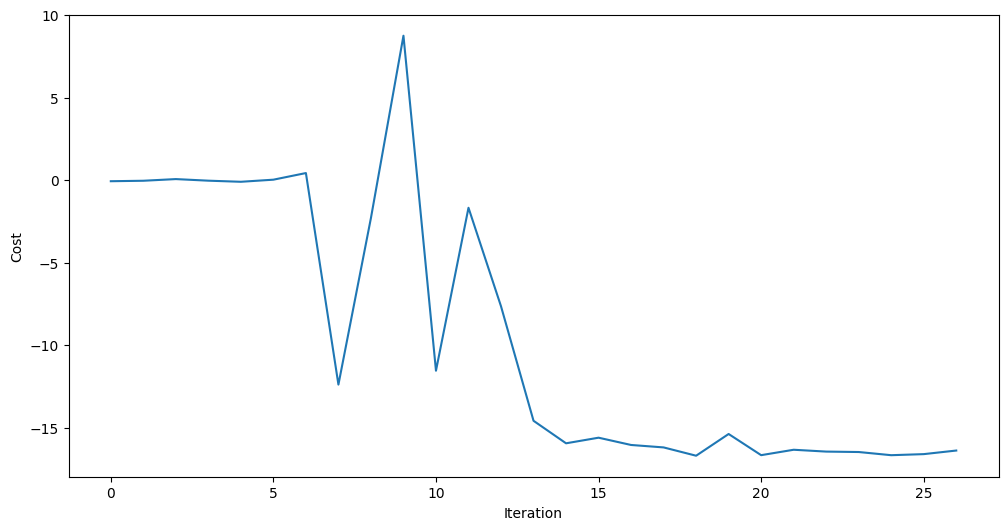

In [70]:
plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()



In [71]:
optimized_circuit = candidate_circuit.assign_parameters(result.x)
optimized_circuit.draw('mpl', fold=False, idle_wires=False)

In [72]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

# If using qiskit-ibm-runtime<0.24.0, change `mode=` to `backend=`
sampler = Sampler(mode=backend)
sampler.options.default_shots = 10000

# # Set simple error suppression/mitigation options
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.dynamical_decoupling.sequence_type = "XY4"
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.num_randomizations = "auto"

pub= (optimized_circuit, )
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{368282: 0.0001, 31323145: 0.0001, 711657: 0.0001, 18017071: 0.0001, 10306120: 0.0001, 21892478: 0.0001, 18595719: 0.0001, 11097246: 0.0001, 4853719: 0.0001, 1382986: 0.0001, 3604349: 0.0001, 26862506: 0.0001, 20750689: 0.0001, 33121605: 0.0001, 28123188: 0.0001, 33122109: 0.0001, 20882214: 0.0001, 23629943: 0.0001, 142335: 0.0001, 18729891: 0.0001, 28049652: 0.0001, 7329546: 0.0001, 7291268: 0.0001, 11173797: 0.0001, 33542178: 0.0001, 11958089: 0.0001, 21457364: 0.0002, 462558: 0.0001, 3993648: 0.0001, 10163739: 0.0002, 17838055: 0.0001, 5586256: 0.0001, 32292892: 0.0001, 6135639: 0.0001, 8927546: 0.0001, 20872376: 0.0001, 8599672: 0.0001, 8123156: 0.0001, 6912432: 0.0001, 21458886: 0.0001, 8404573: 0.0001, 32471188: 0.0001, 24482834: 0.0001, 337272: 0.0001, 14358345: 0.0001, 14341739: 0.0001, 14232182: 0.0001, 20821611: 0.0001, 31406435: 0.0001, 27339709: 0.0001, 18074530: 0.0001, 8562928: 0.0001, 22318362: 0.0001, 6310377: 0.0001, 16725058: 0.0001, 10090377: 0.0001, 9652173: 0.0001,

In [73]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(graph))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

Result bitstring: [0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1]


In [74]:
# import matplotlib.pyplot as plt
# import matplotlib

# matplotlib.rcParams.update({"font.size": 10})
# final_bits = final_distribution_bin
# values = np.abs(list(final_bits.values()))
# top_4_values = sorted(values, reverse=True)[:4]
# positions = []
# for value in top_4_values:
#     positions.append(np.where(values == value)[0])
# fig = plt.figure(figsize=(11, 6))
# ax = fig.add_subplot(1, 1, 1)
# plt.xticks(rotation=45)
# plt.title("Result Distribution")
# plt.xlabel("Bitstrings (reversed)")
# plt.ylabel("Probability")
# ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")
# for p in positions:
#     ax.get_children()[int(p)].set_color("tab:purple")
# plt.show()

Cut value = 52.0


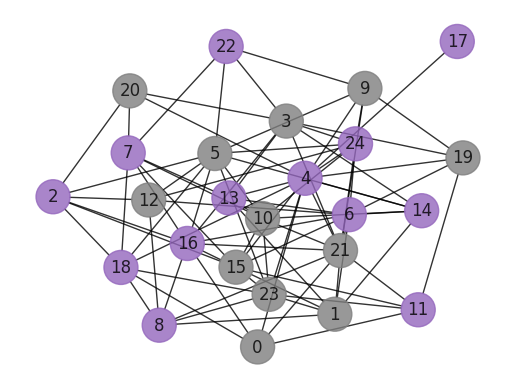

In [75]:
print(f"Cut value = {evaluate_cut(graph, most_likely_bitstring)}")
plot_graph_cut(graph, most_likely_bitstring)

In [ ]:
import numpy as np
import networkx as nx
from qiskit import QuantumCircuit
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit.circuit.library import RYGate
from scipy.linalg import eigh

# 1. Generate or load your graph
G = nx.erdos_renyi_graph(5, p=0.5)
adj_matrix = nx.adjacency_matrix(G).todense()

# 2. Compute Laplacian matrix
def laplacian_matrix(graph):
    return np.diag([d for _, d in graph.degree()]) - nx.adjacency_matrix(graph).todense()

L = laplacian_matrix(G)

# 3. Compute eigenvalues/vectors (sorted ascending)
eigvals, eigvecs = eigh(L)
max_cut_eigenvector = eigvecs[:, -2]  # Second largest eigenvector

# 4. Project to 2D (simplified GW-style projection)
projected = np.column_stack([
    np.real(max_cut_eigenvector),
    np.imag(max_cut_eigenvector)
])

# 5. Normalize and compute angles [0, π]
norms = np.linalg.norm(projected, axis=1)
normalized = projected / norms[:, np.newaxis]
thetas = 2 * np.arctan2(normalized[:,1], normalized[:,0])  # [-π, π] => [0, 2π]

# 6. Create warm-start circuit
def warm_start_circuit(thetas):
    qc = QuantumCircuit(len(thetas))
    for i, theta in enumerate(thetas):
        qc.ry(theta, i)
    return qc

init_qc = warm_start_circuit(thetas)

# 7. Configure QAOA with warm-start
from qiskit_algorithms.utils import algorithm_globals
algorithm_globals.random_seed = 1234

qaoa = QAOA(
    optimizer=COBYLA(),
    reps=2,
    initial_state=init_qc,
    mixer=QAOA.get_mixer("x_mixer")  # Standard mixer (adjust if needed)
)

# 8. Run on quantum simulator/hardware
from qiskit.primitives import Sampler

result = qaoa.compute_minimum_eigenvalue(
    operator=nx.dense.weighted_adjacency_matrix(G, weight="weight"),
    sampler=Sampler()
)

print("Optimal parameters:", result.optimal_parameters)
print("Expected cut value:", result.best_measurement['value'])
